# Did you like the movie? - Multiple Linear Regression

In this stage we will perform a multiple linear regression analysis in order to predict a movie's fan rating based on all the information we have about the movie.  We will use the `statsmodels` approach, both with and without considering an intercept.

## Import libraries

As usual, we load the libraries we need and configure our plots.

In [ ]:
# Data wrangling
# ==============================================================================
import pandas as pd
import numpy as np

In [ ]:
# Plots
# ==============================================================================
import matplotlib.pyplot as plt
#from matplotlib import style
import seaborn as sns

In [ ]:
# Preprocessing and modeling
# ==============================================================================
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import root_mean_squared_error
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from scipy import stats

In [ ]:
# Configuring matplotlib and seaborn
# ==========================================================================bb====
from matplotlib.colors import ListedColormap
plt.rcParams['savefig.bbox'] = "tight"
sns.set_style('whitegrid') # or plt.style.use('ggplot')
sns.set_palette('viridis')

In [ ]:
# For a list of colormaps uncomment the following lines
#from matplotlib import colormaps
#sorted(list(colormaps))

In [ ]:
# Configuring warnings
# ==============================================================================
# If you want to suppress warnings uncomment the following lines
#import warnings
#warnings.filterwarnings('ignore')

## Loading the dataset

We load here our clean dataset

In [ ]:
movies = pd.read_csv('team1_movies_data_604_EDA.csv', index_col='Title')
movies.head()

,Year,Runtime,Genre,Budget,Revenue,Personal,IMDb,Rotten_Tomatoes,Metacritic,Filmaffinity,Fans
Title,,,,,,,,,,,
The Godfather (1972),1972,175,Gangster,6.0,250.0,96,92,97,90,90,92.625000
The Dark Knight (2008),2008,152,Superhero,185.0,1000.0,100,91,94,89,86,88.214286
Pulp Fiction (1994),1994,154,Gangster,8.0,213.0,84,88,92,86,87,86.000000
The Shawshank Redemption (1994),1994,142,Drama,25.0,28.0,84,93,89,91,87,92.000000
Fight Club (1999),1999,139,Crime,68.0,101.0,87,88,81,86,87,85.266667


Since we want to predict the popularity of a movie based on this data, we will use `Fans` as our predicted variable, while all the other numerical variables will be the predictors. We calculate the mean of `Fans` which later we'll be using for checking the validity of the model

In [ ]:
mean_predicted_variable = movies['Fans'].mean()
mean_predicted_variable

np.float64(81.72828358033374)

We must modify column names removing spaces and special symbols, since the methods of **statsmodels** require variable names with no spaces nor special characters (this is the reason why we changed the column names in the data cleaning stage of our project). We will also convert `Year` to a categorical variable (`str`).

In [ ]:
movies['Year']=movies['Year'].astype(int).astype(str)

We also display a statistical description of our data frame.

In [ ]:
movies.describe()

,Runtime,Budget,Revenue,Personal,IMDb,Rotten_Tomatoes,Metacritic,Filmaffinity,Fans
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,127.389222,128.659281,569.456287,81.508982,74.790419,81.239521,72.790419,67.227545,81.728284
std,17.374628,85.083043,367.634521,11.177575,7.759046,14.775920,7.759046,9.283796,5.576548
min,92.000000,2.500000,3.600000,40.000000,53.000000,40.000000,51.000000,46.000000,63.600000
25%,117.000000,52.000000,300.300000,76.000000,69.000000,73.500000,67.000000,60.000000,78.027778
50%,127.000000,149.000000,505.000000,80.000000,75.000000,85.000000,73.000000,67.000000,83.000000
75%,139.500000,185.000000,784.800000,90.000000,80.000000,93.000000,78.000000,74.000000,85.853571
max,176.000000,383.000000,1671.000000,100.000000,93.000000,100.000000,91.000000,90.000000,92.625000


## Relations between variables

The first step in developing a multiple linear model is to study the relationship that exists between the different variables. This information is very useful when identifying which are the best predictors for the model, and for detecting collinearity between predictors.

In [ ]:
# Correlation between numerical columns
# ==============================================================================
corr_matrix = movies.select_dtypes(include=['float64', 'int']).corr(method='pearson')

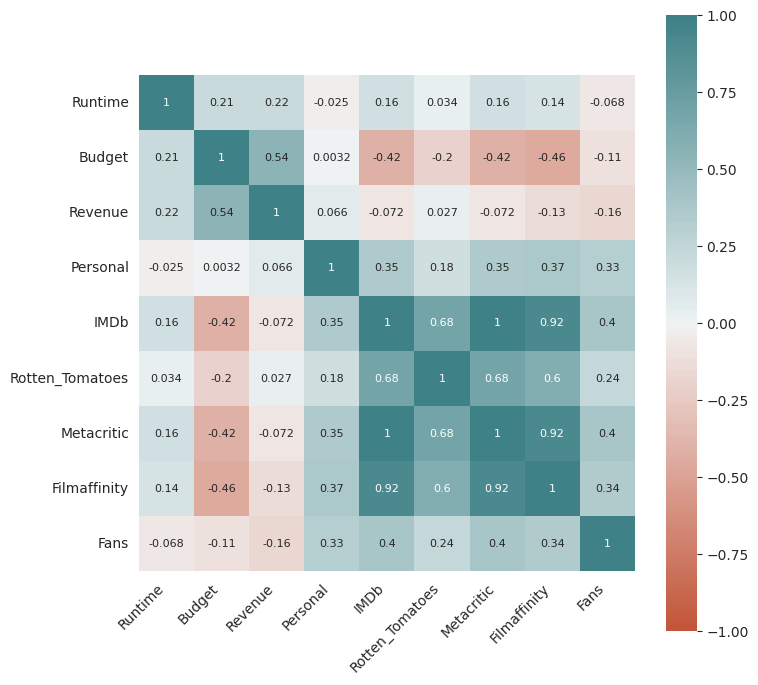

In [ ]:
# Heatmap for correlation matrix
# ==============================================================================
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 8))

sns.heatmap(
    corr_matrix,
    annot     = True,
    cbar      = True,
    annot_kws = {"size": 8},
    vmin      = -1,
    vmax      = 1,
    center    = 0,
    cmap      = sns.diverging_palette(20, 200, n=200),
    square    = True,
    ax        = ax
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation = 45,
    horizontalalignment = 'right',
)

ax.tick_params(labelsize = 10)

In [ ]:
corr_matrix

,Runtime,Budget,Revenue,Personal,IMDb,Rotten_Tomatoes,Metacritic,Filmaffinity,Fans
Runtime,1.000000,0.213783,0.217114,-0.025159,0.158975,0.033917,0.158975,0.139609,-0.067758
Budget,0.213783,1.000000,0.544968,0.003197,-0.418650,-0.202588,-0.418650,-0.458404,-0.112684
Revenue,0.217114,0.544968,1.000000,0.066382,-0.072083,0.027351,-0.072083,-0.133550,-0.158559
Personal,-0.025159,0.003197,0.066382,1.000000,0.353401,0.179551,0.353401,0.369424,0.326091
IMDb,0.158975,-0.418650,-0.072083,0.353401,1.000000,0.680106,1.000000,0.924351,0.397500
Rotten_Tomatoes,0.033917,-0.202588,0.027351,0.179551,0.680106,1.000000,0.680106,0.602288,0.235399
Metacritic,0.158975,-0.418650,-0.072083,0.353401,1.000000,0.680106,1.000000,0.924351,0.397500
Filmaffinity,0.139609,-0.458404,-0.133550,0.369424,0.924351,0.602288,0.924351,1.000000,0.337014
Fans,-0.067758,-0.112684,-0.158559,0.326091,0.397500,0.235399,0.397500,0.337014,1.000000


We will display a heatmap that only shows the entries where the correlation of the corresponding variables is larger than 60% in absolute value.

In [ ]:
high_corr_matrix = corr_matrix[abs(corr_matrix > 0.6)]

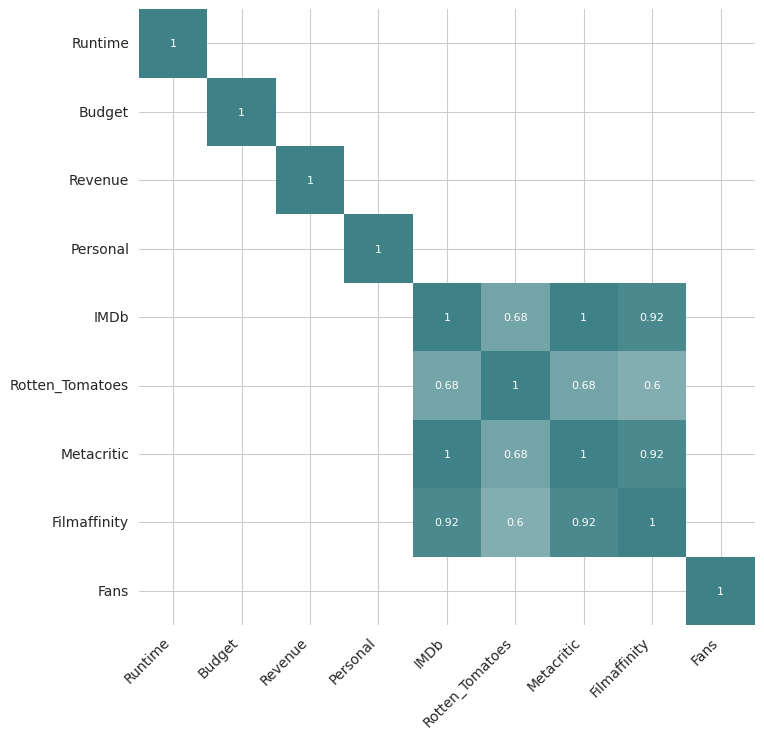

In [ ]:
# Heatmap for correlation matrix - large values
# ==============================================================================
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 8))

sns.heatmap(
    high_corr_matrix,
    annot     = True,
    cbar      = False,
    annot_kws = {"size": 8},
    vmin      = -1,
    vmax      = 1,
    center    = 0,
    cmap      = sns.diverging_palette(20, 200, n=200),
    square    = True,
    ax        = ax
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation = 45,
    horizontalalignment = 'right',
)

ax.tick_params(labelsize = 10)

We observe that the highest correlation is between `IMDb` and `Filmaffinity`, `Metacritic` and `Filmaffinity`;followed by the correlation between `Metacritic` and `Rotten_Tomatoes`, `IMDb` and `Rotten_Tomatoes`. This indicates that perhaps, after fitting our model, we can eliminate one or two of those variables, given that they exhibit a degree of colinearity.

Now we will show the correlation between our predicted variable, `Fans`, with all the predictors.

In [ ]:
fans_corr_matrix = corr_matrix[['Fans']].transpose()

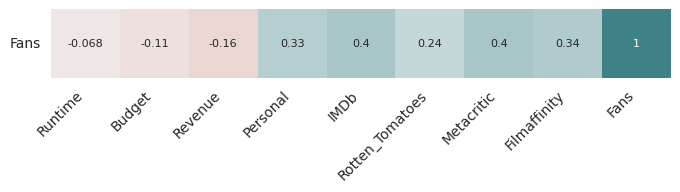

In [ ]:
# Heatmap for correlation matrix - large values
# ==============================================================================
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 8))

sns.heatmap(
    fans_corr_matrix,
    annot     = True,
    cbar      = False,
    annot_kws = {"size": 8},
    vmin      = -1,
    vmax      = 1,
    center    = 0,
    cmap      = sns.diverging_palette(20, 200, n=200),
    square    = True,
    ax        = ax
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation = 45,
    horizontalalignment = 'right'
)
ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation = 0,
    horizontalalignment = 'right'
)

ax.tick_params(labelsize = 10)

We observe that `Runtime` has the lowest correlation with `Fans`, so that variable is not a significant predictor, and we may need to remove it from the fitted model.

## Distribution of numerical variables

Now, we show a histogram and distribution plot for each of our numerical variables.

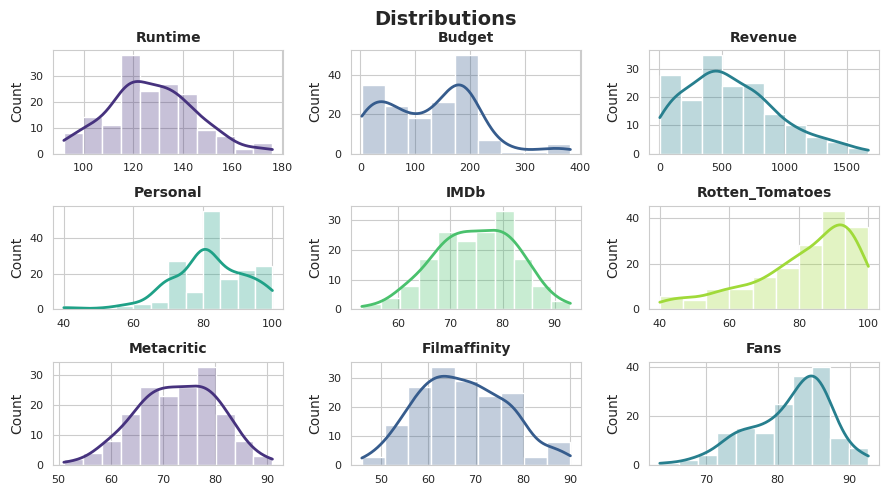

In [ ]:
# Distribution plots for each numerical variable
# ==============================================================================
#
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(9, 5))
axes = axes.flat
columnas_numeric = movies.select_dtypes(include=['float64', 'int']).columns

for i, colum in enumerate(columnas_numeric):
    sns.histplot(
        data    = movies,
        x       = colum,
        stat    = 'count',
        kde     = True,
        color   = (list(plt.rcParams['axes.prop_cycle'])*2)[i]["color"],
        line_kws= {'linewidth': 2},
        alpha   = 0.3,
        ax      = axes[i]
    )
    axes[i].set_title(colum, fontsize = 10, fontweight = "bold")
    axes[i].tick_params(labelsize = 8)
    axes[i].set_xlabel("")



fig.tight_layout()
plt.subplots_adjust(top = 0.9)
fig.suptitle('Distributions', fontsize = 14, fontweight = "bold");

We note that `IMDb` and `Metacritic`, are the variables with the highest correlation with `Fans`, they have a similar distribution as `Fans`, so most likely it will be the most significant predictor. We will confirm or refute this hypothesis when we fit our model.

## Fitting the model

We fit a multiple linear regression model with the objective of predicting sales in function of the budget assigned for the three ad channels.

We will use **Statsmodels** for fitting the linear regression model, presenting all variants of the process as we did with simple linear regression.

### Setting up the data for training and testing the model

In [ ]:
# Train-test Splitting
# ==============================================================================
X = movies.select_dtypes(include=['float64', 'int'])
model_columns = X.columns
X.drop(['Fans'], axis = 1, inplace=True)
y = movies['Fans']

X_train, X_test, y_train, y_test = train_test_split(
                                        X,
                                        y.values.reshape(-1,1),
                                        train_size   = 0.8,
                                        random_state = 1234,
                                        shuffle      = True
                                    )

In [ ]:
data_train = pd.DataFrame(
                   np.hstack((X_train, y_train)),
                   columns=model_columns
              )

In [ ]:
model_columns

Index(['Runtime', 'Budget', 'Revenue', 'Personal', 'IMDb', 'Rotten_Tomatoes',
       'Metacritic', 'Filmaffinity', 'Fans'],
      dtype='object')

### Model fitting with a formula

In [ ]:
# Model fitting using a formula
# ==============================================================================
modelf = smf.ols(formula = 'Fans ~ Runtime + Budget + Revenue + Personal + IMDb + Rotten_Tomatoes\
        + Metacritic + Filmaffinity', data = data_train)
modelf = modelf.fit()
modelf.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   Fans   R-squared:                       0.268
Model:                            OLS   Adj. R-squared:                  0.226
Method:                 Least Squares   F-statistic:                     6.522
Date:                Fri, 05 Dec 2025   Prob (F-statistic):           1.46e-06
Time:                        17:50:49   Log-Likelihood:                -393.51
No. Observations:                 133   AIC:                             803.0
Df Residuals:                     125   BIC:                             826.1
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          17.9197      1.847      9.700      0.000      14.263      21.576
Runtime            -0.0128      0.027     -0.471      0.639      -0.067       0.041
Budget              0.0109      0.007      1.589      0.115      -0.003       0.024
Revenue            -0.0038      0.001     -2.768      0.006      -0.006      -0.001
Personal            0.0877      0.040      2.211      0.029       0.009       0.166
IMDb               18.1325      1.810     10.018      0.000      14.550      21.715
Rotten_Tomatoes     0.0312      0.041      0.754      0.452      -0.051       0.113
Metacritic        -17.7070      1.887     -9.382      0.000     -21.442     -13.972
Filmaffinity       -0.1594      0.123     -1.300      0.196      -0.402       0.083
==============================================================================
Omnibus:                        7.497   Durbin-Watson:                   1.891
Prob(Omnibus):                  0.024   Jarque-Bera (JB):                7.785
Skew:                          -0.568   Prob(JB):                       0.0204
Kurtosis:                       2.660   Cond. No.                     2.78e+17
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 8.98e-28. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

Elimination order:
Runtime,
Rotten_Tomatoes,
Filmaffinity,
Budget

We see that our model has a very small $R^2$ value (0.226), which means it can explain only 22.6% of the observed `Fans` variability. The *$p$-value* for the model is highly significant (1.46e-06), so we can accept the hypothesis that our model is better than what would be expected of random chance. However, since $R^2$ is small, let's explore the possibility of ignoring the intercept.

In [ ]:
modelf_noint = smf.ols(formula = 'Fans ~ Runtime + Budget + Revenue + Personal + IMDb + Rotten_Tomatoes\
        + Metacritic + Filmaffinity', data = data_train)
modelf_noint = modelf_noint.fit()
modelf_noint.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   Fans   R-squared:                       0.268
Model:                            OLS   Adj. R-squared:                  0.226
Method:                 Least Squares   F-statistic:                     6.522
Date:                Fri, 05 Dec 2025   Prob (F-statistic):           1.46e-06
Time:                        17:50:49   Log-Likelihood:                -393.51
No. Observations:                 133   AIC:                             803.0
Df Residuals:                     125   BIC:                             826.1
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          17.9197      1.847      9.700      0.000      14.263      21.576
Runtime            -0.0128      0.027     -0.471      0.639      -0.067       0.041
Budget              0.0109      0.007      1.589      0.115      -0.003       0.024
Revenue            -0.0038      0.001     -2.768      0.006      -0.006      -0.001
Personal            0.0877      0.040      2.211      0.029       0.009       0.166
IMDb               18.1325      1.810     10.018      0.000      14.550      21.715
Rotten_Tomatoes     0.0312      0.041      0.754      0.452      -0.051       0.113
Metacritic        -17.7070      1.887     -9.382      0.000     -21.442     -13.972
Filmaffinity       -0.1594      0.123     -1.300      0.196      -0.402       0.083
==============================================================================
Omnibus:                        7.497   Durbin-Watson:                   1.891
Prob(Omnibus):                  0.024   Jarque-Bera (JB):                7.785
Skew:                          -0.568   Prob(JB):                       0.0204
Kurtosis:                       2.660   Cond. No.                     2.78e+17
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 8.98e-28. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

Now our model has the same $R^2$ value ($0.226$), which means it can explain 22.6% of the observed sales variability. The *$p$-value* for the model is extremely significant (1.46e-06), so again we can accept the hypothesis that our model is better than what would be expected of random chance. However, unless we have a good reason for ignoring the intercept, we fit the model with intercept.

### Eliminating variables that have no significant predictive power

We observe that the *$p$-value* for several predictors is higher than 0.05, which means that these variables do not significantly contribute to our model. We will follow the procedure of eliminating one predictor at a time, starting with the least significant one, and retraining our model.

The first variable to eliminate is `Runtime`.

In [ ]:
# Model fitting using a formula
# ==============================================================================
# Dropping Runtime
model = smf.ols(formula = 'Fans ~ Budget + Revenue + Personal + IMDb + Rotten_Tomatoes\
        + Metacritic + Filmaffinity', data = data_train)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   Fans   R-squared:                       0.266
Model:                            OLS   Adj. R-squared:                  0.231
Method:                 Least Squares   F-statistic:                     7.619
Date:                Fri, 05 Dec 2025   Prob (F-statistic):           5.45e-07
Time:                        17:50:49   Log-Likelihood:                -393.63
No. Observations:                 133   AIC:                             801.3
Df Residuals:                     126   BIC:                             821.5
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          17.5744      1.690     10.397      0.000      14.229      20.919
Budget              0.0101      0.007      1.524      0.130      -0.003       0.023
Revenue            -0.0038      0.001     -2.875      0.005      -0.006      -0.001
Personal            0.0902      0.039      2.304      0.023       0.013       0.168
IMDb               17.7843      1.647     10.800      0.000      14.526      21.043
Rotten_Tomatoes     0.0344      0.041      0.844      0.400      -0.046       0.115
Metacritic        -17.3646      1.736    -10.002      0.000     -20.800     -13.929
Filmaffinity       -0.1665      0.121     -1.373      0.172      -0.407       0.073
==============================================================================
Omnibus:                        7.703   Durbin-Watson:                   1.903
Prob(Omnibus):                  0.021   Jarque-Bera (JB):                8.028
Skew:                          -0.578   Prob(JB):                       0.0181
Kurtosis:                       2.664   Cond. No.                     1.56e+17
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 2.77e-27. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

Order of elimination:
Rotten_Tomatoes,
Filmaffinity,
Budget

We see that the `Omnibus` and `Cond. No.` parameters change, but more importantly, the $p$-value of all predictors decreased.

We continue eliminating variables until all $p$-values for the predictor coefficients are smaller than 0.05.

In [ ]:
# Model fitting using a formula
# ==============================================================================
# Dropping Rotten_Tomatoes
model = smf.ols(formula = 'Fans ~ Budget + Revenue + Personal + IMDb\
        + Metacritic + Filmaffinity', data = data_train)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   Fans   R-squared:                       0.262
Model:                            OLS   Adj. R-squared:                  0.233
Method:                 Least Squares   F-statistic:                     9.020
Date:                Fri, 05 Dec 2025   Prob (F-statistic):           2.33e-07
Time:                        17:50:49   Log-Likelihood:                -394.00
No. Observations:                 133   AIC:                             800.0
Df Residuals:                     127   BIC:                             817.3
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       17.4275      1.679     10.377      0.000      14.104      20.751
Budget           0.0106      0.007      1.607      0.111      -0.002       0.024
Revenue         -0.0038      0.001     -2.844      0.005      -0.006      -0.001
Personal         0.0867      0.039      2.230      0.028       0.010       0.164
IMDb            17.6583      1.638     10.780      0.000      14.417      20.900
Metacritic     -17.1966      1.723     -9.983      0.000     -20.605     -13.788
Filmaffinity    -0.1614      0.121     -1.334      0.185      -0.401       0.078
==============================================================================
Omnibus:                        6.830   Durbin-Watson:                   1.872
Prob(Omnibus):                  0.033   Jarque-Bera (JB):                7.049
Skew:                          -0.540   Prob(JB):                       0.0295
Kurtosis:                       2.672   Cond. No.                     1.48e+17
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 3.08e-27. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

Order of elimination:
Filmaffinity,
Budget

In [ ]:
# Model fitting using a formula
# ==============================================================================
# Dropping Filmaffinity
model = smf.ols(formula = 'Fans ~ Budget + Revenue + Personal + IMDb\
        + Metacritic', data = data_train)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   Fans   R-squared:                       0.252
Model:                            OLS   Adj. R-squared:                  0.228
Method:                 Least Squares   F-statistic:                     10.77
Date:                Fri, 05 Dec 2025   Prob (F-statistic):           1.49e-07
Time:                        17:50:49   Log-Likelihood:                -394.93
No. Observations:                 133   AIC:                             799.9
Df Residuals:                     128   BIC:                             814.3
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     18.0676      1.614     11.193      0.000      14.874      21.262
Budget         0.0123      0.006      1.893      0.061      -0.001       0.025
Revenue       -0.0037      0.001     -2.759      0.007      -0.006      -0.001
Personal       0.0784      0.039      2.036      0.044       0.002       0.155
IMDb          18.2147      1.589     11.464      0.000      15.071      21.359
Metacritic   -17.9205      1.640    -10.928      0.000     -21.165     -14.676
==============================================================================
Omnibus:                        9.321   Durbin-Watson:                   1.824
Prob(Omnibus):                  0.009   Jarque-Bera (JB):                9.775
Skew:                          -0.634   Prob(JB):                      0.00754
Kurtosis:                       2.607   Cond. No.                     3.02e+17
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 7.34e-28. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

Order of elimination: Budget

In [ ]:
# Model fitting using a formula
# ==============================================================================
# Dropping Budget
model = smf.ols(formula = 'Fans ~ Revenue + Personal + IMDb\
        + Metacritic', data = data_train)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   Fans   R-squared:                       0.231
Model:                            OLS   Adj. R-squared:                  0.213
Method:                 Least Squares   F-statistic:                     12.90
Date:                Fri, 05 Dec 2025   Prob (F-statistic):           2.01e-07
Time:                        17:50:49   Log-Likelihood:                -396.76
No. Observations:                 133   AIC:                             801.5
Df Residuals:                     129   BIC:                             813.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     19.2147      1.511     12.715      0.000      16.225      22.205
Revenue       -0.0022      0.001     -2.012      0.046      -0.004   -3.66e-05
Personal       0.0891      0.038      2.317      0.022       0.013       0.165
IMDb          19.3373      1.489     12.989      0.000      16.392      22.283
Metacritic   -19.0921      1.534    -12.448      0.000     -22.127     -16.057
==============================================================================
Omnibus:                       10.383   Durbin-Watson:                   1.856
Prob(Omnibus):                  0.006   Jarque-Bera (JB):               10.219
Skew:                          -0.626   Prob(JB):                      0.00604
Kurtosis:                       2.473   Cond. No.                     3.06e+17
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 6.87e-28. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

### Confidence intervals for the coefficients

Now that we've obtained our most significant model, we explore the confidence intervals for the coefficients.

In [ ]:
# Confidence intervals for the coefficients
# ==============================================================================
intervals_ci = model.conf_int(alpha=0.05)
intervals_ci.columns = ['2.5%', '97.5%']
intervals_ci

,2.5%,97.5%
Intercept,16.224794,22.204563
Revenue,-0.004342,-0.000037
Personal,0.013019,0.165275
IMDb,16.391668,22.282907
Metacritic,-22.126727,-16.057413


## Residual analysis

We perform a basic residual analysis. In order for the model to be adequate, the sum of residues must be close to zero.

In [ ]:
# Residual analysis
# ==============================================================================
y_train = y_train.flatten()
prediction_train = model.predict(exog = X_train)
residues_train   = prediction_train - y_train

In [ ]:
residues_train.sum()

np.float64(-2.7462476737127872e-11)

We see that the sum of residues is negative, and very close to zero. This indicates that residues are also very close to zero, but slightly skewed to the left. We perform a graphical residual analysis to determine if the conditions of homoscedasticity and normality of the residues is satisfied.

### Graphs

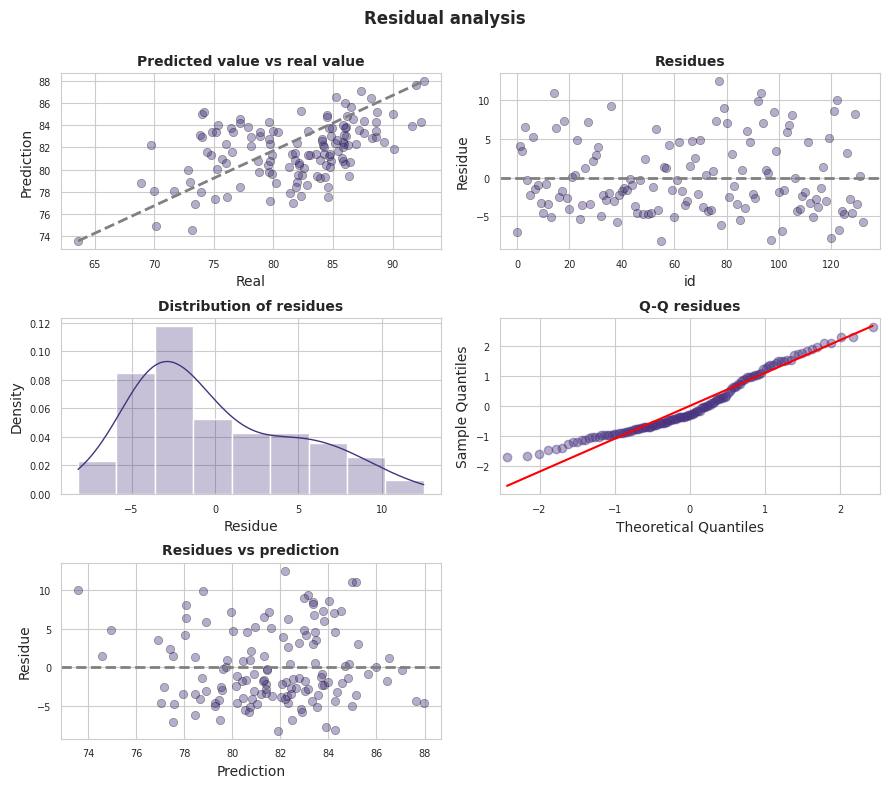

In [ ]:
# Graphs
# ==============================================================================
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(9, 8))

# axes[0,0]
sns.scatterplot(
    x          = y_train,
    y          = prediction_train,
    edgecolors = (0, 0, 0),
    alpha      = 0.4,
    ax         = axes[0, 0]
)

points = [(y_train.min(),prediction_train.min()), (y_train.max(), prediction_train.max())]  # x, y coordinates
line_data = pd.DataFrame(points, columns=['x', 'y'])
sns.lineplot(
    x          = 'x',
    y          = 'y',
    data       = line_data,
    linestyle  = '--',
    color      = 'gray',
    lw         = 2,
    ax         = axes[0, 0]
)

axes[0, 0].set_title('Predicted value vs real value', fontsize = 10, fontweight = "bold")
axes[0, 0].set_xlabel('Real')
axes[0, 0].set_ylabel('Prediction')
axes[0, 0].tick_params(labelsize = 7)

# axes[0,1]
sns.scatterplot(
    x          = list(range(len(y_train))),
    y          = residues_train,
    edgecolors = (0, 0, 0),
    alpha      = 0.4,
    ax         = axes[0, 1]
)

axes[0, 1].axhline(y = 0, linestyle = '--', color = 'gray', lw=2)
axes[0, 1].set_title('Residues', fontsize = 10, fontweight = "bold")
axes[0, 1].set_xlabel('id')
axes[0, 1].set_ylabel('Residue')
axes[0, 1].tick_params(labelsize = 7)

# axes[1, 0]
sns.histplot(
    data    = residues_train,
    stat    = "density",
    kde     = True,
    line_kws= {'linewidth': 1},
    alpha   = 0.3,
    ax      = axes[1, 0]
)

axes[1, 0].set_title('Distribution of residues', fontsize = 10,
                     fontweight = "bold")
axes[1, 0].set_xlabel("Residue")
axes[1, 0].tick_params(labelsize = 7)

# axes[1, 1]
sm.qqplot(
    residues_train,
    fit   = True,
    line  = 'q',
    ax    = axes[1, 1],
    alpha = 0.4,
    lw    = 2
)

axes[1, 1].set_title('Q-Q residues', fontsize = 10, fontweight = "bold")
axes[1, 1].tick_params(labelsize = 7)

# axes[2, 0]
sns.scatterplot(
    x          = prediction_train,
    y          = residues_train,
    edgecolors = (0, 0, 0),
    alpha      = 0.4,
    ax         = axes[2, 0]
)

axes[2, 0].axhline(y = 0, linestyle = '--', color = 'grey', lw=2)
axes[2, 0].set_title('Residues vs prediction', fontsize = 10, fontweight = "bold")
axes[2, 0].set_xlabel('Prediction')
axes[2, 0].set_ylabel('Residue')
axes[2, 0].tick_params(labelsize = 7)

# Eliminate empty axes
fig.delaxes(axes[2,1])

fig.tight_layout()
plt.subplots_adjust(top=0.9)
fig.suptitle('Residual analysis', fontsize = 12, fontweight = "bold");

We observe that the residues are distributed randomly both when plotted in the order they appear and in order of increasing prediction value, which indicates that homocedasticity is satisfied. However, both the histogram and the Q-Q plot show that the residue distribution is not quite normal, being skewed al little to the left. We check for normality next.

### Normality test

We now verify if the residues follow a normal distribution using to statistical tests: *Shapiro-Wilk test* and *D'Agostino's K-squared test*. The latter includes a summary from **Statsmodels** with the name *Omnibus*.

On both tests, the null hypothesis considers that the data follows a normal distribution. Hence, if the *$p$-value* is not smaller than the selected significance level *alpha* there is no evidence to reject the statement that the data is normally distributed.

In [ ]:
# Shapiro-Wilk test
# ==============================================================================
shapiro_test = stats.shapiro(residues_train)
shapiro_test

ShapiroResult(statistic=np.float64(0.943726402162758), pvalue=np.float64(3.143471184435512e-05))

In [ ]:
# D'Agostino's K-squared test
# ==============================================================================
k2, p_value = stats.normaltest(residues_train)
print(f"Statistic= {k2}, p-value = {p_value}")

Statistic= 10.383041288104778, p-value = 0.005563540214871007


Both tests show some evidence for rejecting the hypothesis that normality is not satisfied, given that *$p$-value* < 0.05.

## Predictions

Now that we have trained our model, we can obtain predictions for new data. Models from **statsmodels** allow us to calculate confidence intervals associated with each prediction.

In [ ]:
# # Predictions with 95% confidence intervals
# ==============================================================================
predictions = model.get_prediction(exog = X_train).summary_frame(alpha=0.05)
predictions.head(4)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,77.555986,0.969267,75.638268,79.473704,67.765332,87.346641
1,78.022905,1.079720,75.886653,80.159158,68.187111,87.858700
2,83.504907,1.089584,81.349138,85.660676,73.664855,93.344958
3,81.327911,0.440137,80.457089,82.198733,71.687496,90.968326


## Model error test

Perhaps one of the best indicators that our model is valid and can be used reliably is the root mean square error (`rmse`) of the residues. As a rule of thumb, the `rmse` should be less than 10% of the mean of the predicted variable.

In [ ]:
# Model error test
# ==============================================================================
predictions = model.predict(exog = X_test)
rmse = root_mean_squared_error(
        y_true  = y_test,
        y_pred  = predictions
       )
print("")
print(f"The test error (rmse) is {rmse}, which is {rmse/mean_predicted_variable*100:.2f}% of the mean of `Fans`.")


The test error (rmse) is 5.426932801531194, which is 6.64% of the mean of `Fans`.


In [ ]:
residues=y_test[:,0]-predictions
residues.sum()
# Should be close to 0

np.float64(-5.028476241948525)

In [ ]:
model.params

,0
Intercept,19.214679
Revenue,-0.002189
Personal,0.089147
IMDb,19.337288
Metacritic,-19.092070


## Interpretating our results

The multiple linear regression that we obtained,

$$Fans = 19.214679 - 0.002189\,Revenue + 0.089147\,Personal + 19.337288\,IMDb - 19.092070\,Metacritic$$

can explain 23.1% of the observed Fans variance (*R-squared*: 0.231, *Adj. R-squared*: 0.213). The *F* test is significant (*$p$-value*: 2.01e-07). Therefore, there is clear evidence that the variance explained by the model is greater than that of random chance.

Normality is not satisfied, so the estimated confidence intervals for the coefficients are not reliable.

The model error test is 5.426932801531194, so the model predictions get farther from the real value by 5.426932801531194 **on average**.

## Making a prediction

Now, we will use our models (with and without interactions) to predict the rating of a movie that is not in the data frame. To that end, we create a list with all movie titles from our dataset, so that we can verify if our chosen test titles are in said dataset.

In [ ]:
titles = movies.index.values.tolist()

I've chosen *Saltburn (2023)*, *Frankenstein (2025)*, *Warfare (2025)*, *Wicked: For Good (2025)*, and *Now You See Me: Now You Don't (2025)* for testing the model.

In [ ]:
# Change movies also
# Remember to choose different movies than the ones in here
'Saltburn (2023)' in titles\
or 'Frankenstein (2025)'.title() in titles or "Warfare (2025)".title() in titles\
or 'Wicked: For Good (2025)' in titles or "Now You See Me: Now You Don't (2025)" in titles

False

Our chosen titles are not in the dataset. Next, we create a dataframe with the necessary information to make a prediction using our model. We will include, besides the `Title` of the movie, their `Revenue_Millions_USD`, `IMDb` rating, and our `Personal` rating.

In [ ]:
# This should also be changed to their correct values
# This should also be changed to their correct values

favorites = pd.DataFrame({
    'Year': [2023, 2025, 2025, 2025, 2025],
    'Runtime': [127, 149, 95, 138, 112],
    'Budget': [20, 120, 20, 165, 90],
    'Revenue': [21.026167, 0.144496, 33.649631, 223.041640, 146.060630],
    'Personal': [80, 90, 92, 79, 79],
    'IMDb': [70, 75, 72, 72, 63],
    'Filmaffinity': [64, 69, 66, 66, 55],
    'Metacritic': [61, 77, 78, 58, 50],
    'Rotten Tomatoes': [72, 86, 92, 69, 61]
},
index=['Saltburn (2023)', 'Frankenstein (2025)', "Warfare (2025)", 'Wicked: For Good (2025)', "Now You See Me: Now You Don't (2025)"])

favorites

,Year,Runtime,Budget,Revenue,Personal,IMDb,Filmaffinity,Metacritic,Rotten Tomatoes
Saltburn (2023),2023,127,20,21.026167,80,70,64,61,72
Frankenstein (2025),2025,149,120,0.144496,90,75,69,77,86
Warfare (2025),2025,95,20,33.649631,92,72,66,78,92
Wicked: For Good (2025),2025,138,165,223.041640,79,72,66,58,69
Now You See Me: Now You Don't (2025),2025,112,90,146.060630,79,63,55,50,61


In [ ]:
model.predict(exog = favorites)

,0
Saltburn (2023),215.294318
Frankenstein (2025),7.444830
Warfare (2025),-69.554159
Wicked: For Good (2025),310.713691
Now You See Me: Now You Don't (2025),289.583192


We observe that predictions aren't consistent across models. This shows our linear model is not appropriate for the data we have, or the surveyed data is ficticious. Also an error can be observed, since the results of the predictions should be float values within 0 and a 100, which represents the Fans score for a certain movie.

## References

Regresión lineal con Python by Joaquín Amat Rodrigo, available under a Attribution 4.0 International (CC BY 4.0) at https://www.cienciadedatos.net/documentos/py10-regresion-lineal-python.html